# 🏦 Bank Customer Churn — Prediction & Analysis

**Goal:** Predict which customers are likely to churn (close their bank account) and surface the business drivers behind churn, so that retention teams can intervene proactively.

**Dataset:** Bank Customer Churn Dataset — 165,034 customers, 14 attributes (demographics, credit score, account balance, tenure, products, activity status).

### Approach
1. Clean & prepare the raw data (drop identifiers, handle types/duplicates)
2. Explore churn patterns visually (EDA)
3. Engineer banking features & handle class imbalance (SMOTE + Pipeline)
4. Train & tune 6 classification models
5. Compare models on Accuracy, Precision, Recall, F1, and ROC-AUC
6. Identify the strongest churn drivers & provide business recommendations

### Table of Contents
1. [Setup & Imports](#1-setup--imports)
2. [Load the Data](#2-load-the-data)
3. [Data Cleaning](#3-data-cleaning)
4. [Exploratory Data Analysis (EDA)](#4-exploratory-data-analysis)
5. [Feature Engineering](#5-feature-engineering)
6. [Preprocessing Pipeline, Split & Class Balancing (SMOTE)](#6-preprocessing-pipeline-split--class-balancing)
7. [Model Training & Hyperparameter Tuning](#7-model-training--hyperparameter-tuning)
8. [Model Evaluation](#8-model-evaluation)
9. [Feature Importance](#9-feature-importance)
10. [Conclusions & Business Recommendations](#10-conclusions--business-recommendations)

==========================================
# 1. Setup & Imports


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report, ConfusionMatrixDisplay)

# Imbalanced-learn Pipeline & SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# 6 Classification Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

import warnings
warnings.filterwarnings('ignore')


==========================================
# 2. Load Dataset


In [2]:
df = pd.read_csv('D:\FastAPI_Project_NTI\Bank.csv')

In [3]:
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()

Shape: 165034 rows x 14 columns


,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15674932,Okwudilichukwu,668,France,Male,33.0,3,0.00,2,1.0,0.0,181449.97,0
1,1,15749177,Okwudiliolisa,627,France,Male,33.0,1,0.00,2,1.0,1.0,49503.50,0
2,2,15694510,Hsueh,678,France,Male,40.0,10,0.00,2,1.0,0.0,184866.69,0
3,3,15741417,Kao,581,France,Male,34.0,2,148882.54,1,1.0,1.0,84560.88,0
4,4,15766172,Chiemenam,716,Spain,Male,33.0,5,0.00,2,1.0,1.0,15068.83,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 165034 entries, 0 to 165033
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   id               165034 non-null  int64  
 1   CustomerId       165034 non-null  int64  
 2   Surname          165034 non-null  str    
 3   CreditScore      165034 non-null  int64  
 4   Geography        165034 non-null  str    
 5   Gender           165034 non-null  str    
 6   Age              165034 non-null  float64
 7   Tenure           165034 non-null  int64  
 8   Balance          165034 non-null  float64
 9   NumOfProducts    165034 non-null  int64  
 10  HasCrCard        165034 non-null  float64
 11  IsActiveMember   165034 non-null  float64
 12  EstimatedSalary  165034 non-null  float64
 13  Exited           165034 non-null  int64  
dtypes: float64(5), int64(6), str(3)
memory usage: 20.4 MB


### 📖 Data Dictionary

| Column Name | Data Type | Description |
| :--- | :--- | :--- |
| **`id`** | Integer | Unique row identifier (dropped before model training). |
| **`CustomerId`** | Integer | Unique customer identifier for each bank client (dropped before training). |
| **`Surname`** | String | Customer's last name (dropped as it does not affect prediction). |
| **`CreditScore`** | Integer | Customer's credit score (the higher the score, the lower the risk of default). |
| **`Geography`** | String | Country where the customer resides (France, Germany, Spain). |
| **`Gender`** | String | Customer's gender (`Male` or `Female`). |
| **`Age`** | Integer | Customer's age in years. |
| **`Tenure`** | Integer | Number of years the customer has been with the bank. |
| **`Balance`** | Float | Current financial balance in the customer's bank account. |
| **`NumOfProducts`** | Integer | Number of bank products or services used by the customer (e.g., accounts, cards). |
| **`HasCrCard`** | Binary (`0`/`1`) | Whether the customer holds a credit card (`1` = Yes, `0` = No). |
| **`IsActiveMember`** | Binary (`0`/`1`) | Whether the customer is an active member interacting continuously with bank services (`1` = Active, `0` = Inactive). |
| **`EstimatedSalary`** | Float | Estimated annual salary of the customer. |
| **`Exited`** *(Target)* | Binary (`0`/`1`) | **Target Variable:** Whether the customer left the bank and closed their account (`1` = Churned/Left, `0` = Retained/Active). |

==========================================
# 3. Summarize Data

In [5]:
df.drop(columns=['id', 'CustomerId']).describe(include='number')

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000
mean,656.454373,38.125888,5.020353,55478.086689,1.554455,0.753954,0.497770,112574.822734,0.211599
std,80.103340,8.867205,2.806159,62817.663278,0.547154,0.430707,0.499997,50292.865585,0.408443
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.000000,0.000000,11.580000,0.000000
25%,597.000000,32.000000,3.000000,0.000000,1.000000,1.000000,0.000000,74637.570000,0.000000
50%,659.000000,37.000000,5.000000,0.000000,2.000000,1.000000,0.000000,117948.000000,0.000000
75%,710.000000,42.000000,7.000000,119939.517500,2.000000,1.000000,1.000000,155152.467500,0.000000
max,850.000000,92.000000,10.000000,250898.090000,4.000000,1.000000,1.000000,199992.480000,1.000000


In [6]:
df.describe(include='object')

,Surname,Geography,Gender
count,165034,165034,165034
unique,2797,3,2
top,Hsia,France,Male
freq,2456,94215,93150


==========================================
# 3. Data Cleaning

In [7]:
df = df.drop(columns=['id', 'CustomerId', 'Surname'])

In [8]:

cat_cols = list(df.select_dtypes(include='object').columns)
for col in cat_cols:
    print(f'{col:18s}: {df[col].unique()}')

Geography         : <ArrowStringArray>
['France', 'Spain', 'Germany']
Length: 3, dtype: str
Gender            : <ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str


In [9]:
cols_to_convert = ['Exited', 'IsActiveMember', 'HasCrCard']
df[cols_to_convert] = df[cols_to_convert].astype(int)
print(df[cols_to_convert].dtypes)

Exited            int64
IsActiveMember    int64
HasCrCard         int64
dtype: object


==========================================
# 4. EDA


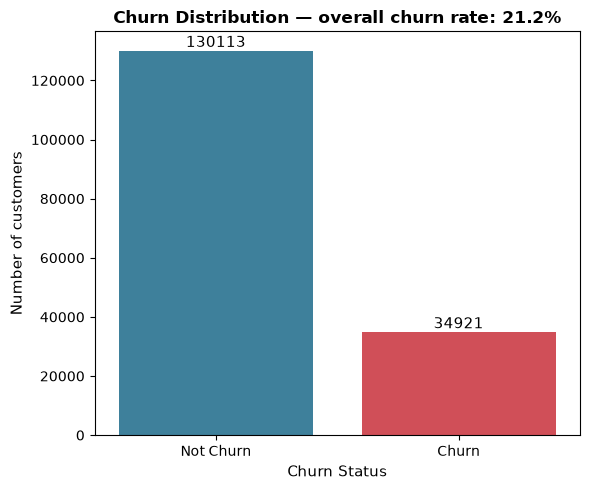

In [10]:
churn_rate = df['Exited'].mean() * 100

plt.figure(figsize=(6, 5))
ax = sns.countplot(x='Exited', data=df, palette=['#2E86AB', '#E63946'])
ax.set_xticklabels(['Not Churn', 'Churn'])
plt.title(f'Churn Distribution — overall churn rate: {churn_rate:.1f}%', fontweight='bold', fontsize=12)
plt.ylabel('Number of customers', fontsize=11)
plt.xlabel('Churn Status', fontsize=11)

# إضافة القيم فوق الأعمدة
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.savefig('churn_distribution.png', dpi=150)
plt.show()

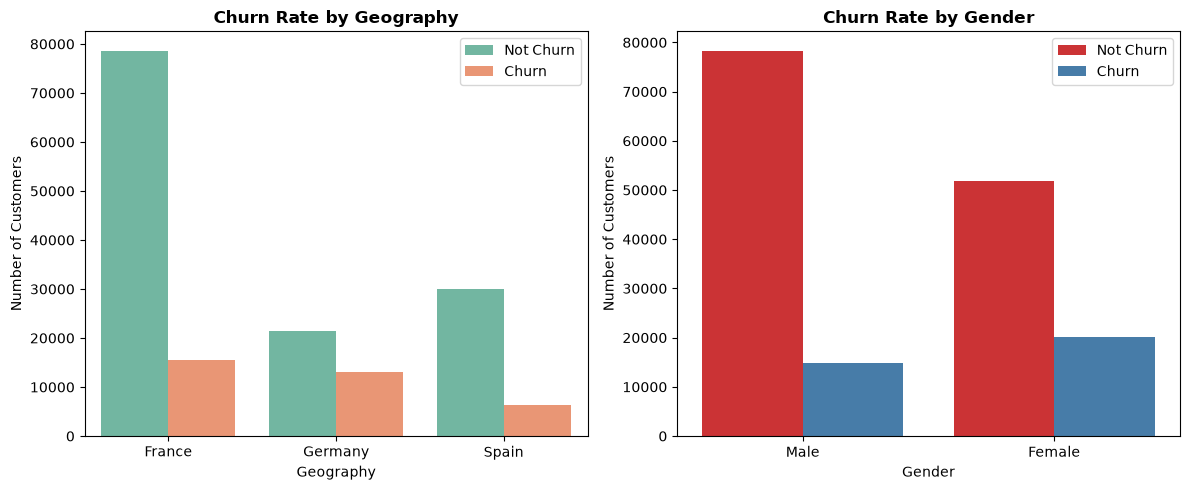

In [11]:
plt.figure(figsize=(12, 5))

# 1. Churn comparison by Geography (Full Column)
plt.subplot(1, 2, 1)
ax1 = sns.countplot(x='Geography', hue='Exited', data=df, palette='Set2', order=['France', 'Germany', 'Spain'])
plt.title('Churn Rate by Geography', fontweight='bold')
plt.ylabel('Number of Customers')
plt.legend(['Not Churn', 'Churn'])

# 2. Churn comparison by Gender
plt.subplot(1, 2, 2)
ax2 = sns.countplot(x='Gender', hue='Exited', data=df, palette='Set1')
plt.title('Churn Rate by Gender', fontweight='bold')
plt.ylabel('Number of Customers')
plt.legend(['Not Churn', 'Churn'])

plt.tight_layout()
plt.savefig('demographics_churn.png', dpi=150)
plt.show()

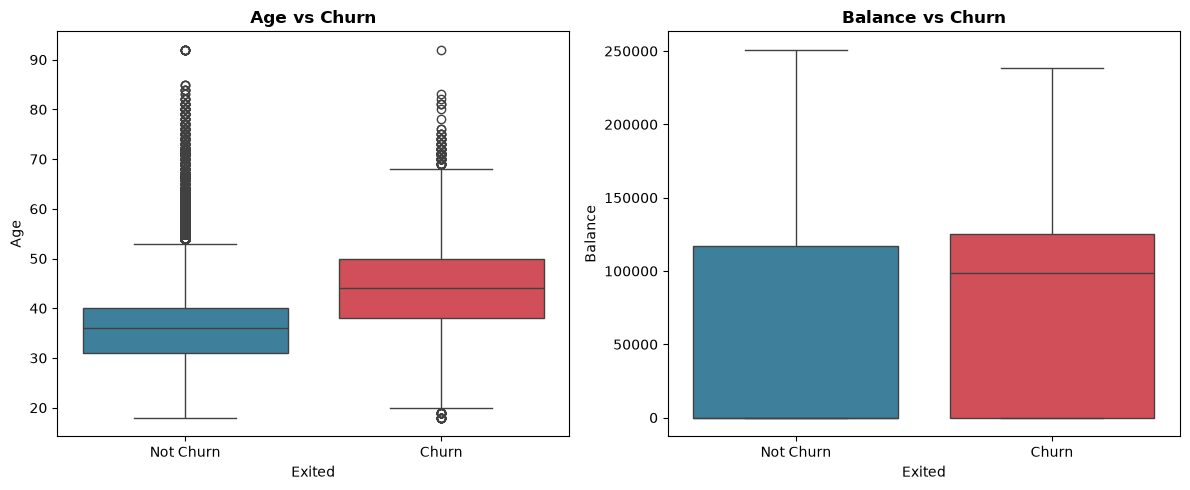

In [12]:
plt.figure(figsize=(12, 5))

# مقارنة الأعمار
plt.subplot(1, 2, 1)
sns.boxplot(x='Exited', y='Age', data=df, palette=['#2E86AB', '#E63946'])
plt.xticks([0, 1], ['Not Churn', 'Churn'])
plt.title('Age vs Churn', fontweight='bold')

# مقارنة الأرصدة
plt.subplot(1, 2, 2)
sns.boxplot(x='Exited', y='Balance', data=df, palette=['#2E86AB', '#E63946'])
plt.xticks([0, 1], ['Not Churn', 'Churn'])
plt.title('Balance vs Churn', fontweight='bold')

plt.tight_layout()
plt.savefig('numeric_features_churn.png', dpi=150)
plt.show()

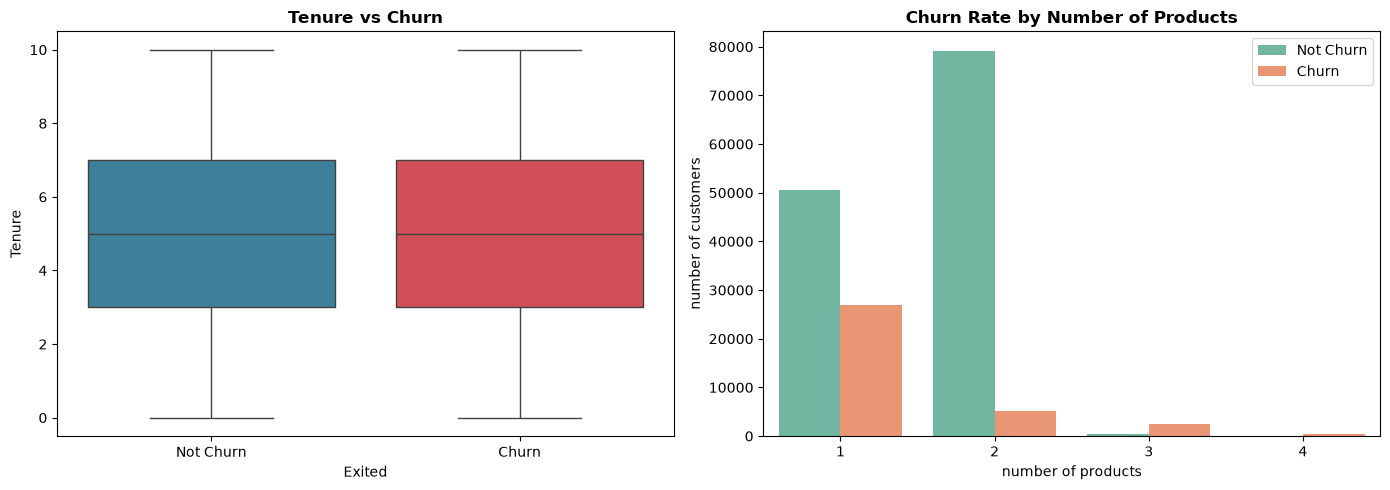

In [13]:
plt.figure(figsize=(14, 5))

# مقارنة مدة الولاء (Tenure)
plt.subplot(1, 2, 1)
sns.boxplot(x='Exited', y='Tenure', data=df, hue='Exited', palette=['#2E86AB', '#E63946'], legend=False)
plt.xticks([0, 1], ['Not Churn', 'Churn'])
plt.title('Tenure vs Churn', fontweight='bold')

# تأثير عدد المنتجات (NumOfProducts)
plt.subplot(1, 2, 2)
ax = sns.countplot(x='NumOfProducts', hue='Exited', data=df, palette='Set2')
plt.title('Churn Rate by Number of Products', fontweight='bold')
plt.ylabel('number of customers')
plt.xlabel('number of products')
plt.legend(['Not Churn', 'Churn'])

plt.tight_layout()
plt.savefig('tenure_products_churn.png', dpi=150)
plt.show()

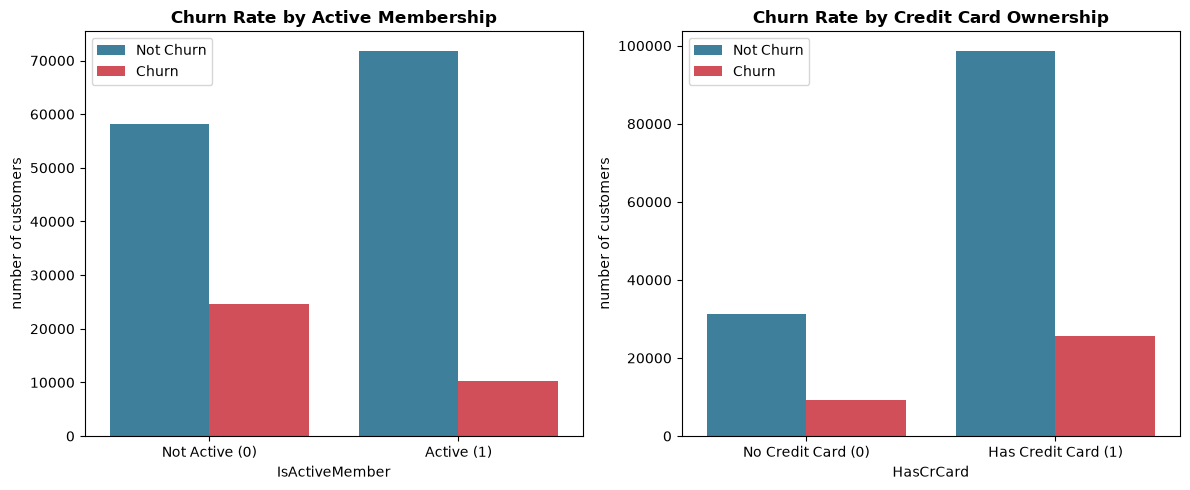

In [14]:
plt.figure(figsize=(12, 5))

# تأثير العضوية النشطة
plt.subplot(1, 2, 1)
ax1 = sns.countplot(x='IsActiveMember', hue='Exited', data=df, palette=['#2E86AB', '#E63946'])
ax1.set_xticklabels(['Not Active (0)', 'Active (1)'])
plt.title('Churn Rate by Active Membership', fontweight='bold')
plt.ylabel('number of customers')
plt.legend(['Not Churn', 'Churn'])

# تأثير بطاقة الائتمان
plt.subplot(1, 2, 2)
ax2 = sns.countplot(x='HasCrCard', hue='Exited', data=df, palette=['#2E86AB', '#E63946'])
ax2.set_xticklabels(['No Credit Card (0)', 'Has Credit Card (1)'])
plt.title('Churn Rate by Credit Card Ownership', fontweight='bold')
plt.ylabel('number of customers')
plt.legend(['Not Churn', 'Churn'])

plt.tight_layout()
plt.savefig('activity_credit_churn.png', dpi=150)
plt.show()

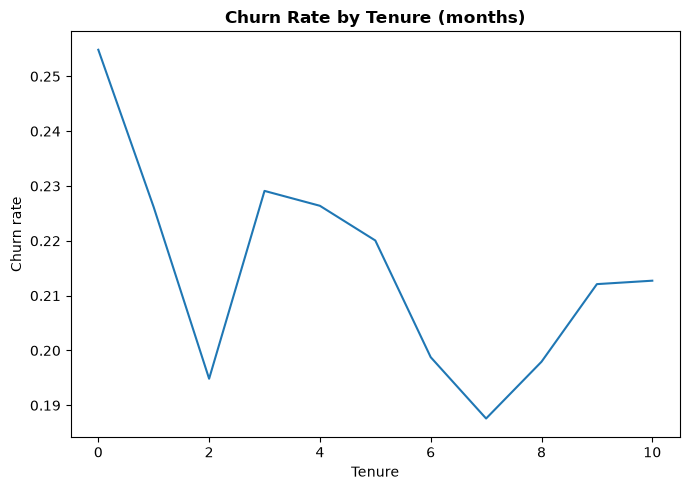

In [15]:

plt.figure(figsize=(7, 5))
sns.lineplot(data=df, x='Tenure', y='Exited', errorbar=None)
plt.title('Churn Rate by Tenure (months)', fontweight='bold')
plt.ylabel('Churn rate')
plt.tight_layout()
plt.show()

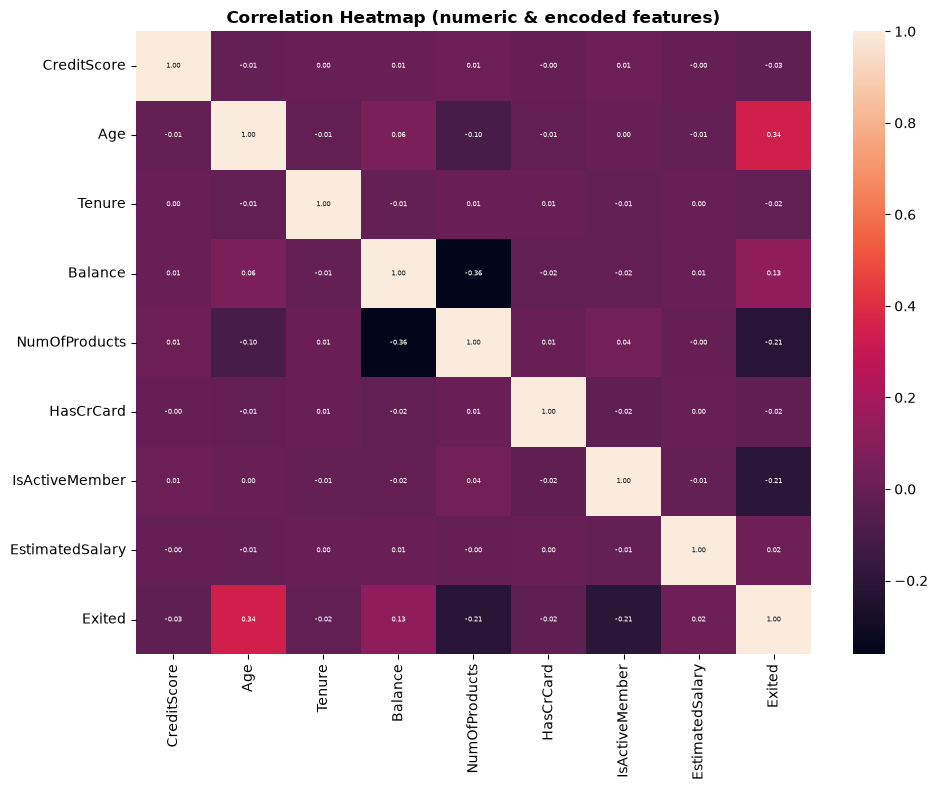

In [16]:
num_cols = list(df.select_dtypes(include='number').columns)

plt.figure(figsize=(10 , 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='rocket',
            annot_kws={"size": 5}, cbar=True)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.title('Correlation Heatmap (numeric & encoded features)', fontweight='bold')
plt.tight_layout()
plt.show()

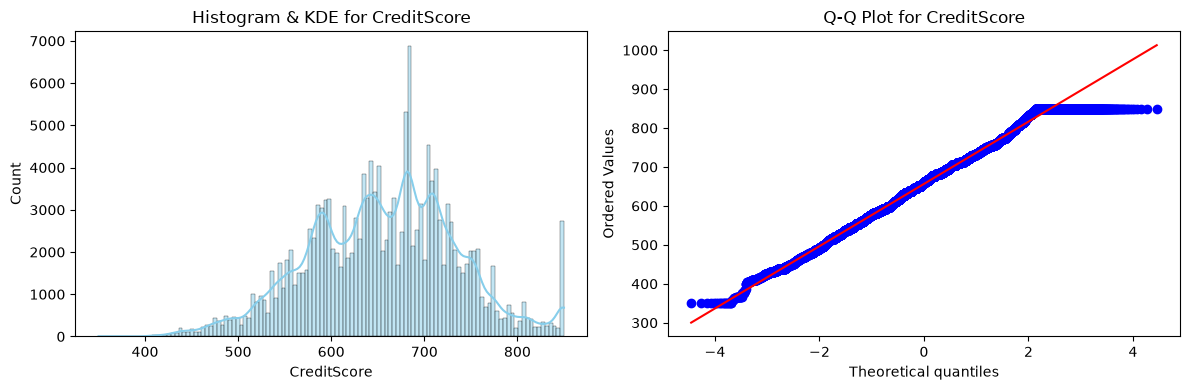

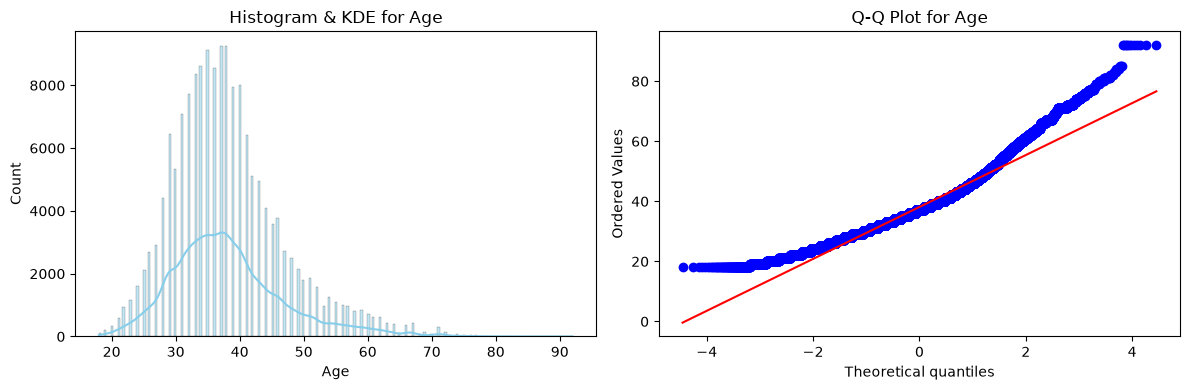

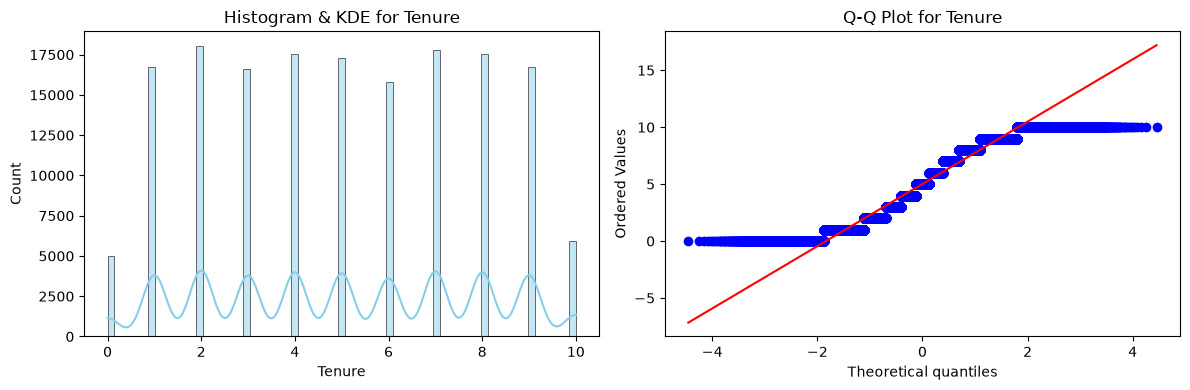

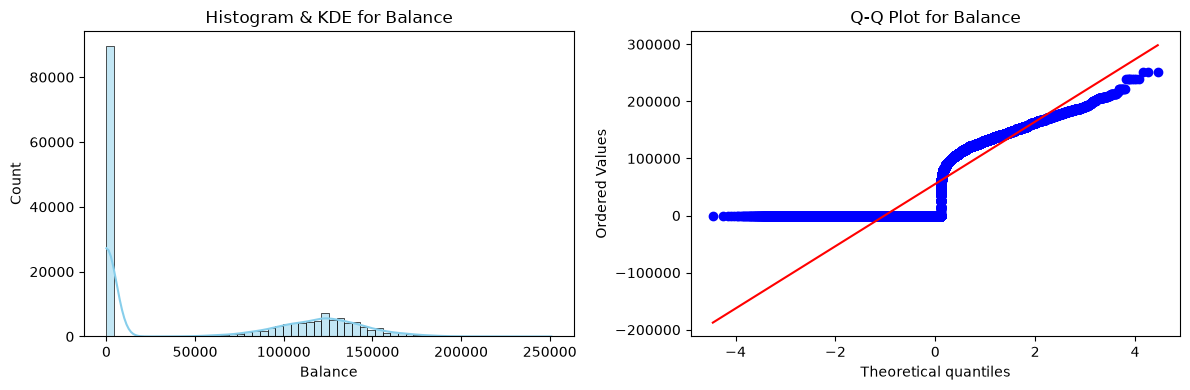

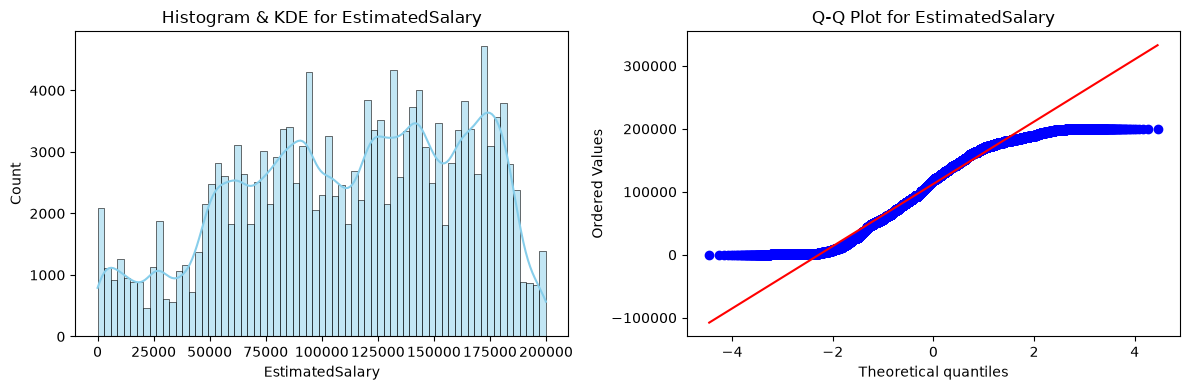



Column: CreditScore
Statistics = 129.989, p-value = 0.00000
-> النتيجة: CreditScore لا تتبع التوزيع الطبيعي (Not Normally Distributed)
--------------------------------------------------
Column: Age
Statistics = 24165.430, p-value = 0.00000
-> النتيجة: Age لا تتبع التوزيع الطبيعي (Not Normally Distributed)
--------------------------------------------------
Column: Tenure
Statistics = 102610.882, p-value = 0.00000
-> النتيجة: Tenure لا تتبع التوزيع الطبيعي (Not Normally Distributed)
--------------------------------------------------
Column: Balance
Statistics = 811358.273, p-value = 0.00000
-> النتيجة: Balance لا تتبع التوزيع الطبيعي (Not Normally Distributed)
--------------------------------------------------
Column: EstimatedSalary
Statistics = 19399.789, p-value = 0.00000
-> النتيجة: EstimatedSalary لا تتبع التوزيع الطبيعي (Not Normally Distributed)
--------------------------------------------------


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# افترض أن لديك DataFrame باسم df وأن الأعمدة العددية كما في الصورة:
# numeric_columns = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']

numeric_columns = ['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary']

# 1. الفحص البصري (Visual Inspection) باستخدام Histogram و Q-Q Plot
for col in numeric_columns:
    plt.figure(figsize=(12, 4))

    # الرسم الأول: Histogram مع منحنى الكثافة (KDE)
    plt.subplot(1, 2, 1)
    sns.histplot(df[col], kde=True, color='skyblue')
    plt.title(f'Histogram & KDE for {col}')

    # الرسم الثاني: Q-Q Plot لمقارنة البيانات بالتوزيع الطبيعي النظري
    plt.subplot(1, 2, 2)
    stats.probplot(df[col], dist="norm", plot=plt)
    plt.title(f'Q-Q Plot for {col}')

    plt.tight_layout()
    plt.show()

print("\n" + "="*50 + "\n")

# 2. الاختبارات الإحصائية (Statistical Tests)
# سنستخدم اختبار D'Agostino's K-squared test أو Shapiro-Wilk test
for col in numeric_columns:
    # ملاحظة: إذا كان حجم البيانات كبيراً جداً (أكثر من 5000 صف)، يفضل استخدام normaltest بدلاً من shapiro
    stat, p_value = stats.normaltest(df[col].dropna())

    print(f'Column: {col}')
    print(f'Statistics = {stat:.3f}, p-value = {p_value:.5f}')

    # القاعدة العامة: إذا كان p-value أكبر من 0.05، فالبيانات تتبع التوزيع الطبيعي
    if p_value > 0.05:
        print(f'-> النتيجة: {col} تتبع التوزيع الطبيعي (Normally Distributed)')
    else:
        print(f'-> النتيجة: {col} لا تتبع التوزيع الطبيعي (Not Normally Distributed)')
    print('-' * 50)

==========================================
# 5. Peprocessing

In [18]:
ohe = OneHotEncoder(sparse_output=False, dtype=int)
geo_encoded = ohe.fit_transform(df[['Geography']])

geo_df = pd.DataFrame(geo_encoded, columns=ohe.get_feature_names_out(['Geography']), index=df.index)

df = pd.concat([df.drop(columns=['Geography']), geo_df], axis=1)

In [19]:
if not pd.api.types.is_numeric_dtype(df['Gender']):
    df['Gender'] = df['Gender'].str.strip().map({'Male': 1, 'Female': 0})

In [20]:
print("Remaining object columns:", df.select_dtypes(include=['object']).columns.tolist())
df.head()

Remaining object columns: []


,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_France,Geography_Germany,Geography_Spain
0,668,1,33.0,3,0.00,2,1,0,181449.97,0,1,0,0
1,627,1,33.0,1,0.00,2,1,1,49503.50,0,1,0,0
2,678,1,40.0,10,0.00,2,1,0,184866.69,0,1,0,0
3,581,1,34.0,2,148882.54,1,1,1,84560.88,0,1,0,0
4,716,1,33.0,5,0.00,2,1,1,15068.83,0,0,0,1


In [21]:
df.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_France,Geography_Germany,Geography_Spain
0,668,1,33.0,3,0.00,2,1,0,181449.97,0,1,0,0
1,627,1,33.0,1,0.00,2,1,1,49503.50,0,1,0,0
2,678,1,40.0,10,0.00,2,1,0,184866.69,0,1,0,0
3,581,1,34.0,2,148882.54,1,1,1,84560.88,0,1,0,0
4,716,1,33.0,5,0.00,2,1,1,15068.83,0,0,0,1


==========================================
# 6. Train/Test Split & Scaling Pipeline

In [22]:
X = df.drop('Exited', axis=1)
y = df['Exited']

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [24]:
from sklearn.preprocessing import RobustScaler
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

==========================================
# 7. Models Evaluation

In [25]:
import time
import pandas as pd
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score
)

# 1. SMOTE
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

models = {
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, max_depth=4, learning_rate=0.01, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=4,              # تقييد العمق لمنع الحفظ الأعمى
        min_samples_split=15,     # الحد الأدنى لتقسيم العقدة
        min_samples_leaf=5,       # الحد الأدنى للورقة النهائية
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,              # تقييد عمق الشجرة المفردة
        min_samples_split=15,
        min_samples_leaf=5,
        random_state=42
    ),
    "Logistic Regression": LogisticRegression(max_iter=5000, C=1.0, random_state=42),

    "SVM (Linear)": LinearSVC(max_iter=5000, C=1.0, random_state=42),

    "Naive Bayes": GaussianNB(),
}

results = []

for name, model in models.items():
    print(f"Training and evaluating: {name}...")
    start_time = time.time()

    # التدريب على البيانات المتوازنة
    model.fit(X_train_resampled, y_train_resampled)

    # التنبؤ
    y_pred_train = model.predict(X_train_resampled)
    y_pred_test = model.predict(X_test_scaled)

    # حساب الاحتمالات
    if hasattr(model, "predict_proba"):
        y_proba_test = model.predict_proba(X_test_scaled)[:, 1]
    elif hasattr(model, "decision_function"):
        y_proba_test = model.decision_function(X_test_scaled)
    else:
        y_proba_test = y_pred_test

    auc_score = roc_auc_score(y_test, y_proba_test)

    print(f"-> Done in {time.time() - start_time:.2f} seconds\n")

    # حفظ النتائج
    results.append({
        'Model': name,
        'Train Accuracy': accuracy_score(y_train_resampled, y_pred_train),
        'Test Accuracy': accuracy_score(y_test, y_pred_test),
        'Precision (Churn)': precision_score(y_test, y_pred_test, zero_division=0),
        'Recall (Churn)': recall_score(y_test, y_pred_test, zero_division=0),
        'F1 (Churn)': f1_score(y_test, y_pred_test, zero_division=0),
        'ROC-AUC': auc_score,
    })

# بناء الجدول وترتيبه حسب F1
results_df = pd.DataFrame(results).sort_values('F1 (Churn)', ascending=False).reset_index(drop=True)

# عرض الجدول ملوناً
display(results_df.style.background_gradient(cmap='Greens', subset=['F1 (Churn)', 'ROC-AUC', 'Recall (Churn)']))

Training and evaluating: Gradient Boosting...
-> Done in 115.53 seconds

Training and evaluating: Random Forest...
-> Done in 27.56 seconds

Training and evaluating: Decision Tree...
-> Done in 0.50 seconds

Training and evaluating: Logistic Regression...
-> Done in 0.12 seconds

Training and evaluating: SVM (Linear)...
-> Done in 0.31 seconds

Training and evaluating: Naive Bayes...
-> Done in 0.14 seconds



,Model,Train Accuracy,Test Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),ROC-AUC
0,Gradient Boosting,0.801700,0.798285,0.515228,0.789662,0.623587,0.876263
1,Random Forest,0.797257,0.795952,0.511707,0.779210,0.617742,0.870103
2,Decision Tree,0.786598,0.797649,0.515089,0.745418,0.609210,0.861273
3,SVM (Linear),0.750264,0.757445,0.454513,0.731100,0.560545,0.815825
4,Logistic Regression,0.749866,0.755870,0.452562,0.733534,0.559768,0.815863
5,Naive Bayes,0.733298,0.744933,0.436431,0.705326,0.539215,0.811690


In [26]:
results_df = pd.DataFrame(results).sort_values(by='Recall (Churn)', ascending=False)
print("\n--- Model Comparison ---")
display(results_df.style.background_gradient(
    cmap='Blues',
    subset=['Train Accuracy', 'Test Accuracy', 'Precision (Churn)', 'Recall (Churn)', 'F1 (Churn)', 'ROC-AUC']
))


--- Model Comparison ---


,Model,Train Accuracy,Test Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),ROC-AUC
0,Gradient Boosting,0.801700,0.798285,0.515228,0.789662,0.623587,0.876263
1,Random Forest,0.797257,0.795952,0.511707,0.779210,0.617742,0.870103
2,Decision Tree,0.786598,0.797649,0.515089,0.745418,0.609210,0.861273
3,Logistic Regression,0.749866,0.755870,0.452562,0.733534,0.559768,0.815863
4,SVM (Linear),0.750264,0.757445,0.454513,0.731100,0.560545,0.815825
5,Naive Bayes,0.733298,0.744933,0.436431,0.705326,0.539215,0.811690


==========================================
# 8. Models Enhancement

In [27]:
X = df.drop(['Exited','CreditScore','HasCrCard', 'EstimatedSalary'], axis=1)
y = df['Exited']

In [28]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [29]:
from sklearn.preprocessing import RobustScaler
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [30]:
import time
import pandas as pd
from imblearn.over_sampling import SMOTE
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score
)

# 1. SMOTE
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

# تحديد قيمة الـ Threshold المطلوبة (الافتراضي 0.5)
threshold = 0.4  # غيّر القيمة دي حسب هدفك (مثلاً 0.35 أو 0.6)

models = {
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200, max_depth=4, learning_rate=0.01, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=4,
        min_samples_split=15,
        min_samples_leaf=5,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        min_samples_split=15,
        min_samples_leaf=5,
        random_state=42
    )
}

results = []

for name, model in models.items():
    print(f"Training and evaluating: {name} (Threshold = {threshold})...")
    start_time = time.time()

    # التدريب على البيانات المتوازنة
    model.fit(X_train_resampled, y_train_resampled)

    # حساب الاحتمالات للـ Train والـ Test
    y_proba_train = model.predict_proba(X_train_resampled)[:, 1]
    y_proba_test = model.predict_proba(X_test_scaled)[:, 1]

    # تطبيق الـ Threshold الجديد بدلاً من predict()
    y_pred_train = (y_proba_train >= threshold).astype(int)
    y_pred_test = (y_proba_test >= threshold).astype(int)

    auc_score = roc_auc_score(y_test, y_proba_test)

    print(f"-> Done in {time.time() - start_time:.2f} seconds\n")

    results.append({
        'Model': name,
        'Threshold': threshold,
        'Train Accuracy': accuracy_score(y_train_resampled, y_pred_train),
        'Test Accuracy': accuracy_score(y_test, y_pred_test),
        'Precision (Churn)': precision_score(y_test, y_pred_test, zero_division=0),
        'Recall (Churn)': recall_score(y_test, y_pred_test, zero_division=0),
        'F1 (Churn)': f1_score(y_test, y_pred_test, zero_division=0),
        'ROC-AUC': auc_score,
    })

# بناء الجدول وترتيبه حسب F1
results_df = pd.DataFrame(results).sort_values('F1 (Churn)', ascending=False).reset_index(drop=True)

# عرض الجدول ملوناً
display(results_df.style.background_gradient(cmap='Greens', subset=['F1 (Churn)', 'ROC-AUC', 'Recall (Churn)']))

Training and evaluating: Gradient Boosting (Threshold = 0.4)...
-> Done in 111.98 seconds

Training and evaluating: Random Forest (Threshold = 0.4)...
-> Done in 31.44 seconds

Training and evaluating: Decision Tree (Threshold = 0.4)...
-> Done in 0.52 seconds



,Model,Threshold,Train Accuracy,Test Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),ROC-AUC
0,Gradient Boosting,0.400000,0.792843,0.744206,0.446372,0.869416,0.589887,0.883695
1,Decision Tree,0.400000,0.777433,0.734087,0.434366,0.849513,0.574820,0.861494
2,Random Forest,0.400000,0.769493,0.693641,0.400319,0.899341,0.554027,0.871317


In [31]:
import time
import pandas as pd
from imblearn.over_sampling import SMOTE
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score
)

# 1. SMOTE
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

# تحديد قيمة الـ Threshold المطلوبة (الافتراضي 0.5)
threshold = 0.35  # غيّر القيمة دي حسب هدفك (مثلاً 0.35 أو 0.6)

models = {
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, max_depth=3, learning_rate=0.05, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=3,
        min_samples_split=15,
        min_samples_leaf=5,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        min_samples_split=15,
        min_samples_leaf=5,
        random_state=42
    )
}

results = []

for name, model in models.items():
    print(f"Training and evaluating: {name} (Threshold = {threshold})...")
    start_time = time.time()

    # التدريب على البيانات المتوازنة
    model.fit(X_train_resampled, y_train_resampled)

    # حساب الاحتمالات للـ Train والـ Test
    y_proba_train = model.predict_proba(X_train_resampled)[:, 1]
    y_proba_test = model.predict_proba(X_test_scaled)[:, 1]

    # تطبيق الـ Threshold الجديد بدلاً من predict()
    y_pred_train = (y_proba_train >= threshold).astype(int)
    y_pred_test = (y_proba_test >= threshold).astype(int)

    auc_score = roc_auc_score(y_test, y_proba_test)

    print(f"-> Done in {time.time() - start_time:.2f} seconds\n")

    results.append({
        'Model': name,
        'Threshold': threshold,
        'Train Accuracy': accuracy_score(y_train_resampled, y_pred_train),
        'Test Accuracy': accuracy_score(y_test, y_pred_test),
        'Precision (Churn)': precision_score(y_test, y_pred_test, zero_division=0),
        'Recall (Churn)': recall_score(y_test, y_pred_test, zero_division=0),
        'F1 (Churn)': f1_score(y_test, y_pred_test, zero_division=0),
        'ROC-AUC': auc_score,
    })

# بناء الجدول وترتيبه حسب F1
results_df = pd.DataFrame(results).sort_values('F1 (Churn)', ascending=False).reset_index(drop=True)

# عرض الجدول ملوناً
display(results_df.style.background_gradient(cmap='Greens', subset=['F1 (Churn)', 'ROC-AUC', 'Recall (Churn)']))

Training and evaluating: Gradient Boosting (Threshold = 0.35)...
-> Done in 39.54 seconds

Training and evaluating: Random Forest (Threshold = 0.35)...
-> Done in 21.21 seconds

Training and evaluating: Decision Tree (Threshold = 0.35)...
-> Done in 0.27 seconds



,Model,Threshold,Train Accuracy,Test Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),ROC-AUC
0,Gradient Boosting,0.350000,0.793285,0.734026,0.436433,0.882302,0.583993,0.886420
1,Decision Tree,0.350000,0.777433,0.734087,0.434366,0.849513,0.574820,0.861494
2,Random Forest,0.350000,0.723936,0.596783,0.337412,0.939719,0.496539,0.860743


In [32]:
import time
import pandas as pd
from imblearn.over_sampling import SMOTE
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score
)

# 1. SMOTE
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

# تحديد قيمة الـ Threshold المطلوبة (الافتراضي 0.5)
threshold = 0.3  # غيّر القيمة دي حسب هدفك (مثلاً 0.35 أو 0.6)

models = {
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, max_depth=3, learning_rate=0.05, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=3,
        min_samples_split=15,
        min_samples_leaf=5,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        min_samples_split=15,
        min_samples_leaf=5,
        random_state=42
    ),
    "KNN": KNeighborsClassifier(n_jobs=-1),

    "Adaboost": AdaBoostClassifier(random_state=42),
}

results = []
trained_models = {}

for name, model in models.items():
    print(f"Training and evaluating: {name} (Threshold = {threshold})...")
    start_time = time.time()

    # التدريب على البيانات المتوازنة
    model.fit(X_train_resampled, y_train_resampled)
    trained_models[name] = model

    # حساب الاحتمالات للـ Train والـ Test
    y_proba_train = model.predict_proba(X_train_resampled)[:, 1]
    y_proba_test = model.predict_proba(X_test_scaled)[:, 1]

    # تطبيق الـ Threshold الجديد بدلاً من predict()
    y_pred_train = (y_proba_train >= threshold).astype(int)
    y_pred_test = (y_proba_test >= threshold).astype(int)

    auc_score = roc_auc_score(y_test, y_proba_test)

    print(f"-> Done in {time.time() - start_time:.2f} seconds\n")

    results.append({
        'Model': name,
        'Threshold': threshold,
        'Train Accuracy': accuracy_score(y_train_resampled, y_pred_train),
        'Test Accuracy': accuracy_score(y_test, y_pred_test),
        'Precision (Churn)': precision_score(y_test, y_pred_test, zero_division=0),
        'Recall (Churn)': recall_score(y_test, y_pred_test, zero_division=0),
        'F1 (Churn)': f1_score(y_test, y_pred_test, zero_division=0),
        'ROC-AUC': auc_score,
    })

# بناء الجدول وترتيبه حسب F1
results_df = pd.DataFrame(results).sort_values('F1 (Churn)', ascending=False).reset_index(drop=True)

# عرض الجدول ملوناً
display(results_df.style.background_gradient(cmap='Greens', subset=['F1 (Churn)', 'ROC-AUC', 'Recall (Churn)']))

Training and evaluating: Gradient Boosting (Threshold = 0.3)...
-> Done in 50.92 seconds

Training and evaluating: Random Forest (Threshold = 0.3)...
-> Done in 25.62 seconds

Training and evaluating: Decision Tree (Threshold = 0.3)...
-> Done in 0.51 seconds

Training and evaluating: KNN (Threshold = 0.3)...
-> Done in 12.85 seconds

Training and evaluating: Adaboost (Threshold = 0.3)...
-> Done in 9.02 seconds



,Model,Threshold,Train Accuracy,Test Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),ROC-AUC
0,Decision Tree,0.300000,0.777433,0.734087,0.434366,0.849513,0.574820,0.861494
1,KNN,0.300000,0.862172,0.751931,0.450166,0.778637,0.570499,0.820550
2,Gradient Boosting,0.300000,0.773340,0.685855,0.395078,0.912514,0.551417,0.886420
3,Random Forest,0.300000,0.694092,0.539007,0.310323,0.964204,0.469530,0.860743
4,Adaboost,0.300000,0.535445,0.269549,0.224219,0.996850,0.366093,0.874642


In [33]:
results_df = pd.DataFrame(results).sort_values(by='Recall (Churn)', ascending=False)
print("\n--- Model Comparison ---")
display(results_df.style.background_gradient(
    cmap='Blues',
    subset=['Train Accuracy', 'Test Accuracy', 'Precision (Churn)', 'Recall (Churn)', 'F1 (Churn)', 'ROC-AUC']
))


--- Model Comparison ---


,Model,Threshold,Train Accuracy,Test Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),ROC-AUC
4,Adaboost,0.300000,0.535445,0.269549,0.224219,0.996850,0.366093,0.874642
1,Random Forest,0.300000,0.694092,0.539007,0.310323,0.964204,0.469530,0.860743
0,Gradient Boosting,0.300000,0.773340,0.685855,0.395078,0.912514,0.551417,0.886420
2,Decision Tree,0.300000,0.777433,0.734087,0.434366,0.849513,0.574820,0.861494
3,KNN,0.300000,0.862172,0.751931,0.450166,0.778637,0.570499,0.820550


==========================================
# 9. Feature Importance

Most Important Feature: Age
Importance Score: 0.4617686248989807


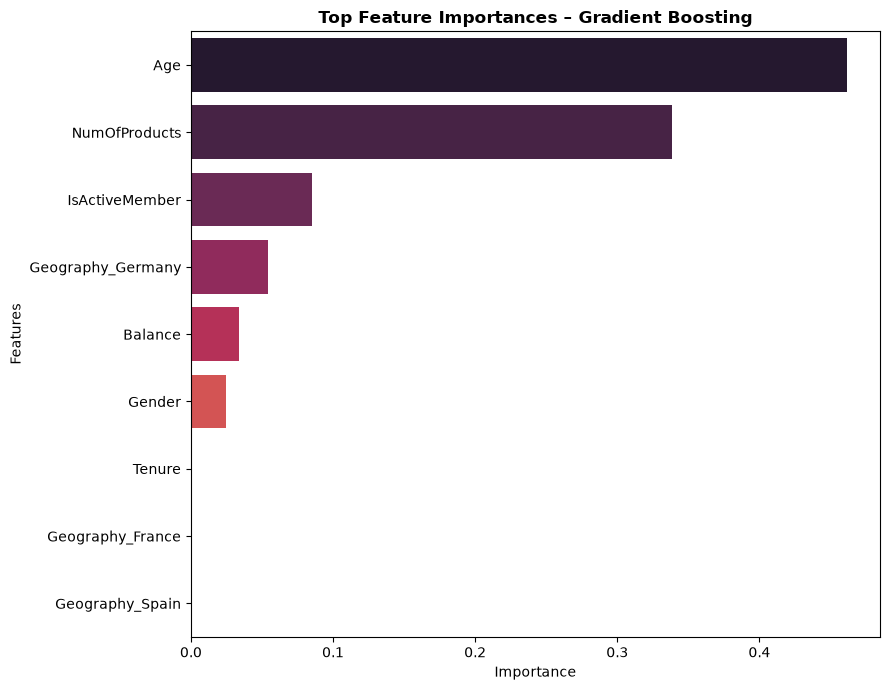

In [37]:
xgb_model = models['Gradient Boosting']

importances = pd.Series(xgb_model.feature_importances_, index=X.columns).sort_values(ascending=False)

print("Most Important Feature:", importances.index[0])
print("Importance Score:", importances.values[0])

plt.figure(figsize=(9, 7))
sns.barplot(x=importances.values, y=importances.index, palette='rocket')
plt.title('Top Feature Importances – Gradient Boosting', fontweight='bold')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.tight_layout()

plt.savefig('gradient_boosting_feature_importance.png', dpi=150)
plt.show()

==========================================
# 10. Conclusions & Business Recommendations

Modeling summary:
1. All six models were trained on SMOTE-balanced data and evaluated on an untouched, stratified test set.
2. The best-performing model (see the table in Section 8) offers the strongest trade-off between catching churners (Recall) and avoiding false alarms (Precision).
3. Tree-based ensembles (Random Forest / Adaboost) tend to give the best ranking quality (ROC-AUC) and the clearest feature-importance signal.

Top churn drivers observed (Based on your Gradient Boosting feature importance results: Age, NumOfProducts, IsActiveMember, Geography):
1. Age (Age) — The model indicates that customer age is the most dominant factor influencing churn, with specific age brackets showing significantly higher propensity to leave.
2. Number of Products (NumOfProducts) — The number of products or services held by a customer directly impacts their loyalty and likelihood of staying with the platform.
3. Active Membership (IsActiveMember) — Inactive members exhibit a substantially higher risk of churning compared to active users.
4. Geography (Geography_Germany) — Geographic location (such as customers based in Germany) stands out as a prominent regional indicator for customer attrition.

Recommended actions:
1. Targeted Engagement for Age Groups: Design tailored marketing campaigns and customized offerings targeted at the specific age groups identified as most vulnerable to churn.
2. Product Bundling & Cross-selling: Encourage customers to adopt multiple products or services to increase stickiness and decrease the likelihood of account closure.
3. Re-engagement Campaigns: Launch proactive campaigns and exclusive incentives to re-engage inactive members before they decide to leave.
4. Proactive Watchlist: Leverage the trained model's churn-probability scores to build a proactive "at-risk customer" watchlist for the retention team.

In [39]:
import joblib

selected_model_name = "Gradient Boosting"
best_model = trained_models[selected_model_name]

model_artifacts = {
    'model_name': selected_model_name,
    'model': best_model,
    'scaler': scaler,
    'threshold': threshold,
    'features': list(X.columns)
}

# 3. حفظ الملف بصيغة .pkl
joblib.dump(model_artifacts, 'best_churn_model.pkl')
print(f"✅ {selected_model_name} saved successfully as 'best_churn_model.pkl'!")

✅ Gradient Boosting saved successfully as 'best_churn_model.pkl'!


In [40]:
import joblib
preprocessing_artifacts = {
    'scaler': scaler,                          # الـ StandardScaler المتدرب على X_train
    'features': list(X.columns),               # الترتيب الدقيق للأعمدة اللي دخلت الموديل
    'gender_map': {'Male': 1, 'Female': 0},    # خريطة تحويل النوع
    'geo_map': {'France': 1, 'Germany': 2, 'Spain': 3}, # (لو استخدمت Label/Manual mapping)
    'threshold': threshold                     # الـ Threshold المعتمد (0.3)
}

joblib.dump(preprocessing_artifacts, 'preprocessor.pkl')
print("✅ Preprocessor & Scaler saved successfully as 'preprocessor.pkl'!")

✅ Preprocessor & Scaler saved successfully as 'preprocessor.pkl'!
